# Fasl · Notebook 1: Collect and clean wheat data
Merges every attached dataset into one clean, de-duplicated, split dataset for two tasks:
- **health**: healthy, brown_rust, yellow_rust, stem_rust, septoria, loose_smut, powdery_mildew
- **stage**: vegetative, flowering, grain_filling, ripening

plus a **not_wheat** reject class.

**How to run:** run Steps 1 to 10 in order, once. Output goes to `/kaggle/working/fasl_clean/`.
Then **Save Version → Save & Run All**, and turn the output into a dataset named `fasl-clean` for Notebook 2.

## Step 1: Settings and attached datasets
Imports, all settings (image size, blur limit, duplicate limits, split ratio) and the list of attached datasets.
Run this first every time the session starts.

In [1]:
import os, re, json, hashlib, random, shutil
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dctn

INPUT_ROOT = Path(os.getenv("FASL_INPUT", "/kaggle/input"))
OUT = Path(os.getenv("FASL_OUT", "/kaggle/working/fasl_clean"))
TMP = Path(os.getenv("FASL_TMP", "/kaggle/tmp/fasl_resized"))  # resized copies on disk, not in RAM
SEED = 42
MAX_SIDE = 512            # resize longest side to this
MIN_SIDE = 64             # drop images whose short side is below this
BLUR_MIN = 15.0           # Laplacian variance below this = too blurry
DUP_DIST = 4              # pHash distance <= this = duplicate (keep one)
GROUP_DIST = 7            # pHash distance <= this = same scene (kept in same split)
MIN_PER_CLASS = 15        # classes below this are dropped
MAX_PER_SOURCE_CLASS = 1500
MAX_NOT_WHEAT = 3000
SPLIT = (0.70, 0.15, 0.15)
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
random.seed(SEED); np.random.seed(SEED)

# Kaggle mounts datasets at /kaggle/input/datasets/<owner>/<name>/ (older layout: /kaggle/input/<name>/)
DS = {}
for d in sorted(INPUT_ROOT.glob("datasets/*/*")) + sorted(INPUT_ROOT.glob("competitions/*")):
    if d.is_dir(): DS[d.name] = d
for d in sorted(INPUT_ROOT.iterdir()):
    if d.is_dir() and d.name not in {"datasets", "notebooks", "competitions", "models"}: DS.setdefault(d.name, d)
print("Attached datasets:")
for k, v in DS.items(): print(f"   {k:45s} {v}")

Attached datasets:
   plantdisease                                  /kaggle/input/datasets/emmarex/plantdisease
   wheatphenology                                /kaggle/input/datasets/hashirsakimdad/wheatphenology
   wheat-plant-diseases                          /kaggle/input/datasets/kushagra3204/wheat-plant-diseases
   wheat-leaf-dataset                            /kaggle/input/datasets/olyadgetch/wheat-leaf-dataset
   wheat-leaf-disease-dataset                    /kaggle/input/datasets/shamimkabirkazim/wheat-leaf-disease-dataset
   yellowrust19-yellow-rust-disease-in-wheat     /kaggle/input/datasets/tolgahayit/yellowrust19-yellow-rust-disease-in-wheat


## Step 2: Which dataset is what
`health` = disease images, `stage` = growth-stage images, `not_wheat` = reject class. Datasets not listed are ignored.
`ALSO_HEALTHY` = stage datasets of disease-free plants; their photos are also used as `health/healthy`, so the health model learns what a healthy ear and field look like.

In [2]:
SOURCES = {
    "wheatphenology": "stage",
    "wheat-leaf-disease-dataset": "health",
    "wheat-plant-diseases": "health",
    "wheat-leaf-dataset": "health",
    "yellowrust19-yellow-rust-disease-in-wheat": "health",
    "plantdisease": "not_wheat",
}
# Stage datasets whose plants are disease-free. Their photos are ALSO added to the health task as
# "healthy", so the health model sees healthy ears and fields, not only healthy leaves.
# Without this, every ear photo looks like loose_smut (the only health class with ear photos).
# Only list a dataset here if you are sure its plants are healthy.
ALSO_HEALTHY = {"wheatphenology"}

missing = [s for s in SOURCES if s not in DS]
assert not missing, f"Not attached / wrong name: {missing}"
print("OK, all sources attached")

OK, all sources attached


## Step 3: Label mapping and image list
Each image's label comes from its folder name, mapped to our classes below.
- Yellow Rust 19 severity: `0` = healthy; `MS`, `S`, `MRMS` = yellow_rust; `R`, `MR` skipped (too few symptoms).
- Diseases we don't predict (aphid, mite, blast, tan spot, ...) are skipped and listed under UNMAPPED.
- Max 1,500 images per class per source, max 3,000 not_wheat.

In [3]:
HEALTH = ["healthy","brown_rust","yellow_rust","stem_rust","septoria","loose_smut","powdery_mildew"]
STAGE = ["vegetative","flowering","grain_filling","ripening"]

ALIASES = {
  "health": {
    "healthy":"healthy","healthy_wheat":"healthy","healthy_leaf":"healthy","normal":"healthy","0":"healthy",
    "brown_rust":"brown_rust","leaf_rust":"brown_rust","brownrust":"brown_rust",
    "yellow_rust":"yellow_rust","stripe_rust":"yellow_rust","yellowrust":"yellow_rust",
    "ms":"yellow_rust","s":"yellow_rust","mrms":"yellow_rust",
    "stem_rust":"stem_rust","black_rust":"stem_rust","stemrust":"stem_rust",
    "septoria":"septoria","septoria_leaf_blotch":"septoria",
    "loose_smut":"loose_smut","smut":"loose_smut",
    "powdery_mildew":"powdery_mildew","mildew":"powdery_mildew",
  },
  "stage": {
    "seedling_and_plant":"vegetative",
    "wheat_flowers":"flowering",
    "plant_with_fruit":"grain_filling",   # TEMP: confirm after viewing images
    "fruit_with_seeds":"ripening",        # TEMP: confirm after viewing images
  },
  "not_wheat": None,                      # every image becomes "not_wheat"
}
GENERIC = {"train","test","val","valid","validation","images","image","img","data","dataset","imgs","jpg"}
SKIP = {"r","mr"}

def norm(s):
    s = re.sub(r"^\d+\.?[\s_-]+", "", s.strip().lower())         # "1. Seedling" -> "seedling"
    s = re.sub(r"[^a-z0-9]+", "_", s).strip("_")
    s = re.sub(r"(_test)?(_valid|_test|_train)$", "", s)          # "smut_test" -> "smut"
    return s or "0"

def label_for(path, task):
    if ALIASES[task] is None: return "not_wheat"
    for part in reversed(path.parent.parts):
        n = norm(part)
        if n in GENERIC: continue
        if n in SKIP: return None
        return ALIASES[task].get(n)
    return None

rows, unmapped = [], Counter()
for src, task in SOURCES.items():
    for p in DS[src].rglob("*"):
        if p.suffix.lower() not in IMG_EXT: continue
        lab = label_for(p, task)
        if lab is None: unmapped[(src, p.parent.name)] += 1; continue
        rows.append(dict(src_path=str(p), source=src, task=task, label=lab))
rows += [dict(r, task="health", label="healthy") for r in list(rows)
         if r["source"] in ALSO_HEALTHY and r["task"] == "stage"]
raw = pd.DataFrame(rows).sample(frac=1, random_state=SEED)
raw = raw.groupby(["source","label"]).head(MAX_PER_SOURCE_CLASS)
raw = pd.concat([raw[raw.task != "not_wheat"], raw[raw.task == "not_wheat"].head(MAX_NOT_WHEAT)], ignore_index=True)

print(raw.groupby(["task","label"]).size().to_string())
print("\nUNMAPPED (skipped) folders:")
for k, v in unmapped.most_common(): print("  ", k, v)

task       label         
health     brown_rust        2597
           healthy           4172
           loose_smut        1679
           powdery_mildew    1151
           septoria          1660
           stem_rust          646
           yellow_rust       4474
not_wheat  not_wheat         1500
stage      flowering           63
           grain_filling      185
           ripening           238
           vegetative          19

UNMAPPED (skipped) folders:
   ('yellowrust19-yellow-rust-disease-in-wheat', 'MR') 3064
   ('yellowrust19-yellow-rust-disease-in-wheat', 'R') 2861
   ('wheat-plant-diseases', 'Aphid') 903
   ('wheat-plant-diseases', 'Leaf Blight') 842
   ('wheat-plant-diseases', 'Mite') 800
   ('wheat-plant-diseases', 'Tan spot') 770
   ('wheat-plant-diseases', 'Blast') 647
   ('wheat-plant-diseases', 'Common Root Rot') 614
   ('wheat-plant-diseases', 'Fusarium Head Blight') 611
   ('wheat-plant-diseases', 'Stem fly') 234
   ('wheatphenology', '5. Wheat Fruits only') 55
   ('

## Step 4: Check, fix and resize every image (slow, run once)
Opens each image, fixes rotation, converts to RGB, drops broken or tiny images, resizes to 512 px and saves a copy to disk.
Also computes a hash (for duplicates) and a blur score. Takes 5 to 15 minutes.

In [4]:
def phash(img):
    g = np.asarray(img.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float32)
    d = dctn(g, norm="ortho")[:8, :8]
    bits = (d > np.median(d)).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

def blur_score(img):
    g = np.asarray(img.convert("L").resize((256, 256)), dtype=np.float32)
    lap = (-4*g[1:-1,1:-1] + g[:-2,1:-1] + g[2:,1:-1] + g[1:-1,:-2] + g[1:-1,2:])
    return float(lap.var())

def process(src_path):
    try:
        b = Path(src_path).read_bytes()
        img = Image.open(src_path); img.load()
        img = ImageOps.exif_transpose(img).convert("RGB")
    except Exception:
        return {"status": "broken"}
    if min(img.size) < MIN_SIDE:
        return {"status": "too_small"}
    img.thumbnail((MAX_SIDE, MAX_SIDE))
    sha = hashlib.sha256(b).hexdigest()
    tmp = TMP / f"{sha}.jpg"
    if not tmp.exists(): img.save(tmp, quality=92)
    return {"status": "ok", "sha": sha, "phash": phash(img), "blur": blur_score(img),
            "w": img.width, "h": img.height, "tmp": str(tmp)}

TMP.mkdir(parents=True, exist_ok=True)
log = Counter(); recs = []
with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
    for i, (r, res) in enumerate(zip(raw.itertuples(index=False), ex.map(process, raw.src_path, chunksize=64))):
        if res["status"] != "ok": log[res["status"]] += 1; continue
        res.pop("status"); recs.append({**r._asdict(), **res})
        if i % 2000 == 0: print(f"  {i}/{len(raw)} done")
df = pd.DataFrame(recs)
print(dict(log), "| valid:", len(df))
print(df.groupby(["task","label"]).size().to_string())

  0/18384 done
  2000/18384 done
  4000/18384 done
  6000/18384 done
  8000/18384 done
  10000/18384 done
  12000/18384 done
  14000/18384 done
  16000/18384 done
  18000/18384 done
{'too_small': 340} | valid: 18044
task       label         
health     brown_rust        2381
           healthy           4172
           loose_smut        1675
           powdery_mildew    1151
           septoria          1660
           stem_rust          646
           yellow_rust       4354
not_wheat  not_wheat         1500
stage      flowering           63
           grain_filling      185
           ripening           238
           vegetative          19


## Step 5: Remove duplicate images
- Same or nearly the same image in one class: keep one copy.
- Same image in two different classes: label conflict, remove all copies.
- Groups similar-looking photos so they stay together in the train / val / test split.

In [5]:
DUP_DIST = 2   # stricter than before: only near-identical copies count as duplicates

def bucket_keys(h, maxd):
    k = maxd + 1; size = 64 // k
    return [(c, (h >> (c*size)) & ((1 << size) - 1)) for c in range(k)]

before = len(df); kept = []
for task, d in df.groupby("task"):
    d = d.sort_values("blur", ascending=False).reset_index(drop=True)   # sharpest copy wins
    buckets = defaultdict(list); keep = []; conflict = set()
    for i, h in enumerate(d.phash):
        match = None
        for key in bucket_keys(h, DUP_DIST):
            for j in buckets[key]:
                if (h ^ d.phash[j]).bit_count() <= DUP_DIST: match = j; break
            if match is not None: break
        if match is None:
            keep.append(i)
            for key in bucket_keys(h, DUP_DIST): buckets[key].append(i)
        elif d.label[match] != d.label[i]:
            conflict.add(match)
    log[f"{task}_label_conflict"] = len(conflict)
    d = d.loc[[i for i in keep if i not in conflict]].reset_index(drop=True)

    parent = list(range(len(d)))
    def f(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    buckets = defaultdict(list)
    for i, h in enumerate(d.phash):
        for key in bucket_keys(h, GROUP_DIST):
            for j in buckets[key]:
                if (h ^ d.phash[j]).bit_count() <= GROUP_DIST: parent[f(i)] = f(j)
            buckets[key].append(i)
    d["group"] = [f"{task}_{f(i)}" for i in range(len(d))]
    kept.append(d)
df = pd.concat(kept, ignore_index=True)
log["duplicates_removed"] = before - len(df) - sum(v for k, v in log.items() if k.endswith("conflict"))
print(dict(log), "| after dedupe:", len(df))
print(df.groupby(["task","label"]).size().to_string())

{'too_small': 340, 'health_label_conflict': 222, 'not_wheat_label_conflict': 0, 'stage_label_conflict': 0, 'duplicates_removed': 7348} | after dedupe: 10474
task       label         
health     brown_rust        1152
           healthy           2434
           loose_smut         260
           powdery_mildew     829
           septoria           446
           stem_rust          300
           yellow_rust       3088
not_wheat  not_wheat         1477
stage      flowering           63
           grain_filling      178
           ripening           228
           vegetative          19


Exact copies (same file bytes): 5097
label
brown_rust        2115
healthy           2223
loose_smut        1599
not_wheat           46
powdery_mildew      40
septoria          1660
stem_rust          434
yellow_rust        404


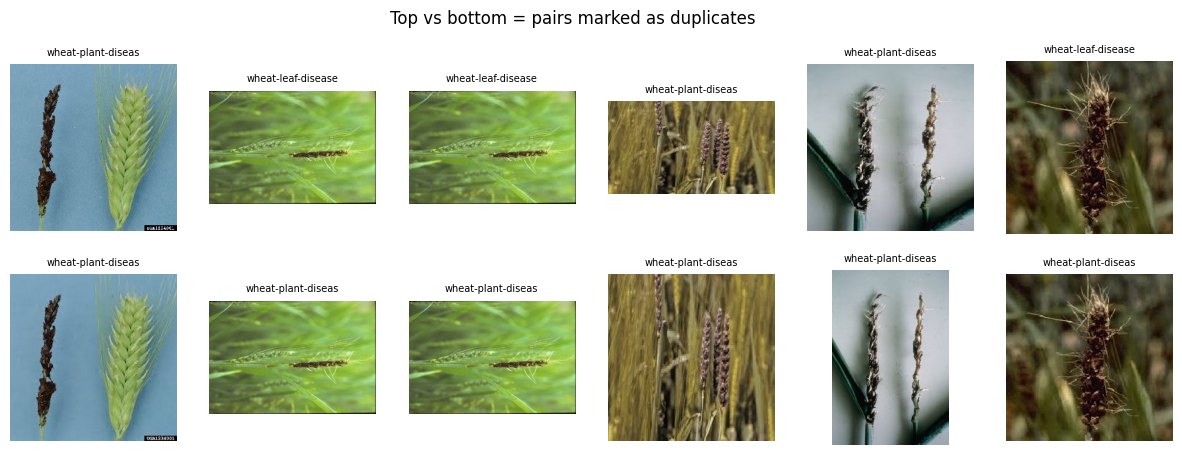

In [6]:
d0 = pd.DataFrame(recs)
print("Exact copies (same file bytes):", int(d0.duplicated("sha").sum()))
print(d0[d0.duplicated("sha", keep=False)].groupby("label").size().to_string())

# show 6 near-duplicate pairs from loose_smut
ls = d0[d0.label == "loose_smut"].reset_index(drop=True)
pairs, seen = [], {}
for i, h in enumerate(ls.phash):
    for key in bucket_keys(h, DUP_DIST):
        if key in seen and (h ^ ls.phash[seen[key]]).bit_count() <= DUP_DIST and ls.sha[i] != ls.sha[seen[key]]:
            pairs.append((seen[key], i)); break
        seen.setdefault(key, i)
    if len(pairs) == 6: break
fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for c, (a, b) in enumerate(pairs):
    ax[0, c].imshow(Image.open(ls.tmp[a])); ax[0, c].set_title(ls.source[a][:18], fontsize=7)
    ax[1, c].imshow(Image.open(ls.tmp[b])); ax[1, c].set_title(ls.source[b][:18], fontsize=7)
for a in ax.flat: a.axis("off")
plt.suptitle("Top vs bottom = pairs marked as duplicates"); plt.show()

## Step 6: Remove blurry images
Removes images below `BLUR_MIN` and shows the 12 least-blurry ones being removed, so we can check the limit.
If good photos appear here, lower `BLUR_MIN` in Step 1 and re-run from Step 4.

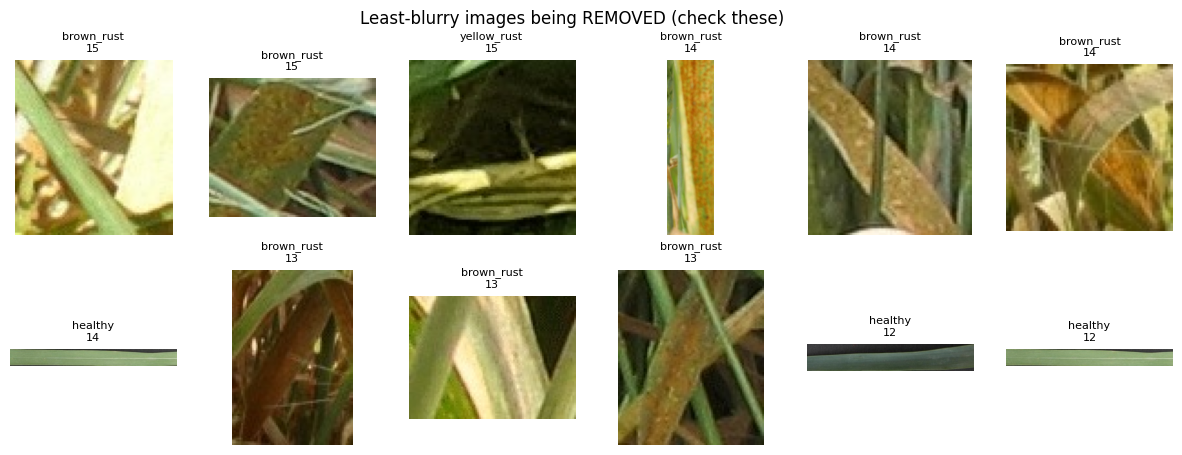

Blurry by class:
 task    label      
health  brown_rust     23
        healthy         4
        yellow_rust     1
removed 28 | remaining 10446


In [7]:
blurry = df[df.blur < BLUR_MIN]
log["blurry"] = len(blurry)
show = blurry.sort_values("blur", ascending=False).head(12)
if len(show):
    fig, ax = plt.subplots(2, 6, figsize=(15, 5))
    for a in ax.flat: a.axis("off")
    for a, r in zip(ax.flat, show.itertuples()):
        a.imshow(Image.open(r.tmp)); a.set_title(f"{r.label}\n{r.blur:.0f}", fontsize=8)
    plt.suptitle("Least-blurry images being REMOVED (check these)"); plt.show()
if len(blurry): print("Blurry by class:\n", blurry.groupby(["task","label"]).size().to_string())
df = df[df.blur >= BLUR_MIN].reset_index(drop=True)
print("removed", len(blurry), "| remaining", len(df))

## Step 7: Drop tiny classes and split into train / val / test
Removes classes with fewer than `MIN_PER_CLASS` images, then splits every class 70 / 15 / 15.
Similar photos (same group from Step 5) always go into the same split, so the test score is honest.

In [8]:
counts = df.groupby(["task","label"]).size()
small = counts[(counts < MIN_PER_CLASS) & (counts.index.get_level_values(0) != "not_wheat")]
if len(small): print("DROPPED (fewer than", MIN_PER_CLASS, "images):\n", small.to_string())
df = df[~df.set_index(["task","label"]).index.isin(small.index)].reset_index(drop=True)

df["split"] = ""
for _, d in df.groupby(["task","label"]):
    groups = d.groupby("group").size().sample(frac=1, random_state=SEED)
    n, acc, out = len(d), 0, {}
    for g, c in groups.items():
        out[g] = "train" if acc < SPLIT[0]*n else ("val" if acc < (SPLIT[0]+SPLIT[1])*n else "test")
        acc += c
    df.loc[d.index, "split"] = d.group.map(out)
print(pd.crosstab([df.task, df.label], df.split, margins=True).to_string())

split                     test  train   val    All
task      label                                   
health    brown_rust       169    791   169   1129
          healthy          364   1701   365   2430
          loose_smut        39    182    39    260
          powdery_mildew   124    581   124    829
          septoria          66    313    67    446
          stem_rust         45    210    45    300
          yellow_rust      463   2161   463   3087
not_wheat not_wheat        221   1034   222   1477
stage     flowering          9     45     9     63
          grain_filling     26    125    27    178
          ripening          34    160    34    228
          vegetative         2     14     3     19
All                       1562   7317  1567  10446


## Step 8: Save the clean dataset
Copies every clean image to `/kaggle/working/fasl_clean/<task>/<split>/<label>/` and writes:
- `manifest.csv`: one row per image (source, label, split, hash, blur score, size)
- `data_report.json`: counts before and after each cleaning step

In [9]:
if OUT.exists(): shutil.rmtree(OUT)
paths = []
for r in df.itertuples():
    p = OUT / r.task / r.split / r.label / f"{r.sha[:16]}.jpg"
    p.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(r.tmp, p); paths.append(str(p.relative_to(OUT)))
df["path"] = paths
out_df = df.drop(columns=["tmp"]).assign(phash=df.phash.map(lambda h: f"{h:016x}"))
out_df.to_csv(OUT / "manifest.csv", index=False)

report = {
  "raw_images": int(len(raw)),
  "removed": {k: int(v) for k, v in log.items()},
  "final_images": int(len(df)),
  "dropped_small_classes": [list(i) for i in small.index],
  "per_class": {f"{t}/{l}": {s: int(n) for s, n in g.split.value_counts().items()} for (t, l), g in df.groupby(["task","label"])},
  "per_source": {k: int(v) for k, v in df.source.value_counts().items()},
  "settings": dict(MAX_SIDE=MAX_SIDE, MIN_SIDE=MIN_SIDE, BLUR_MIN=BLUR_MIN, DUP_DIST=DUP_DIST, GROUP_DIST=GROUP_DIST,
                   MIN_PER_CLASS=MIN_PER_CLASS, MAX_PER_SOURCE_CLASS=MAX_PER_SOURCE_CLASS, MAX_NOT_WHEAT=MAX_NOT_WHEAT,
                   SPLIT=SPLIT, SEED=SEED),
}
(OUT / "data_report.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

{
  "raw_images": 18384,
  "removed": {
    "too_small": 340,
    "health_label_conflict": 222,
    "not_wheat_label_conflict": 0,
    "stage_label_conflict": 0,
    "duplicates_removed": 7348,
    "blurry": 28
  },
  "final_images": 10446,
  "dropped_small_classes": [],
  "per_class": {
    "health/brown_rust": {
      "train": 791,
      "test": 169,
      "val": 169
    },
    "health/healthy": {
      "train": 1701,
      "val": 365,
      "test": 364
    },
    "health/loose_smut": {
      "train": 182,
      "val": 39,
      "test": 39
    },
    "health/powdery_mildew": {
      "train": 581,
      "test": 124,
      "val": 124
    },
    "health/septoria": {
      "train": 313,
      "val": 67,
      "test": 66
    },
    "health/stem_rust": {
      "train": 210,
      "val": 45,
      "test": 45
    },
    "health/yellow_rust": {
      "train": 2161,
      "val": 463,
      "test": 463
    },
    "not_wheat/not_wheat": {
      "train": 1034,
      "val": 222,
      "test": 221


## Step 9: Visual check
Shows 8 random images from every class. Look for wrong labels or junk images and note them down.

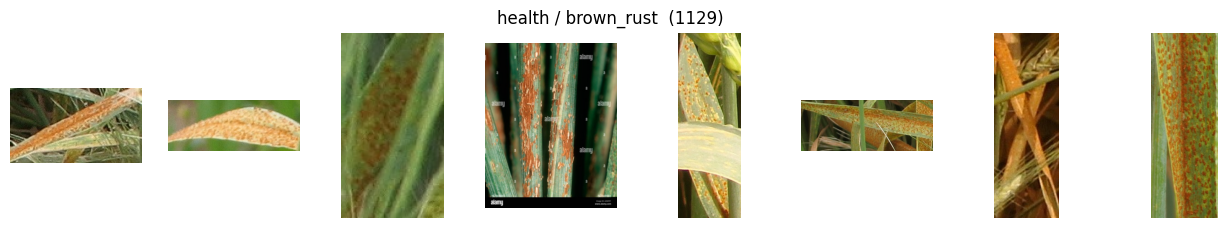

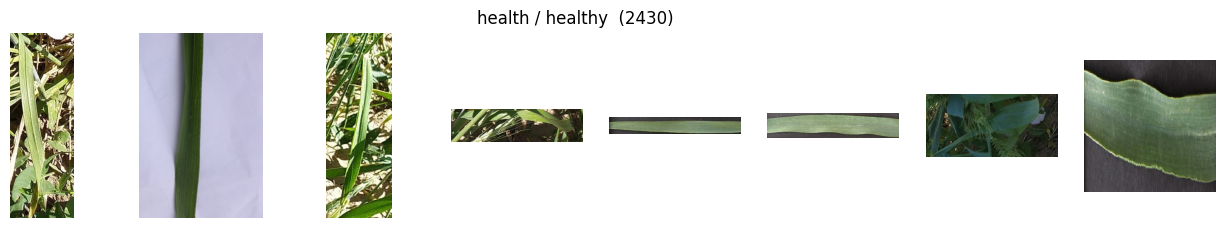

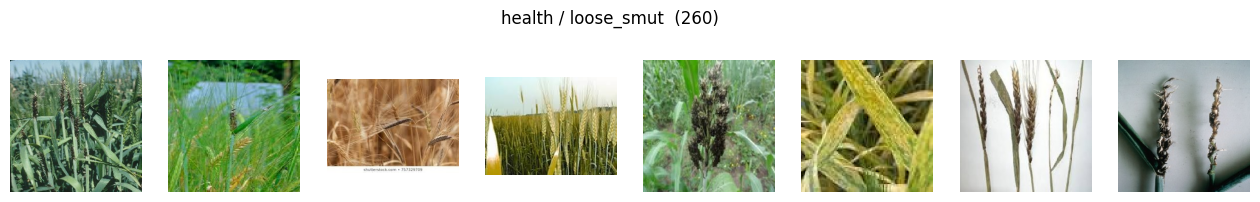

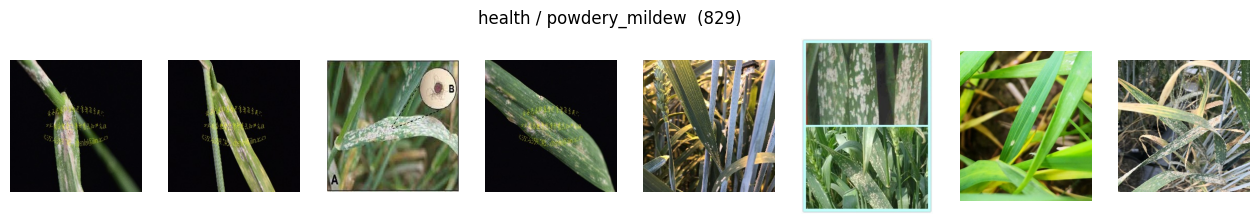

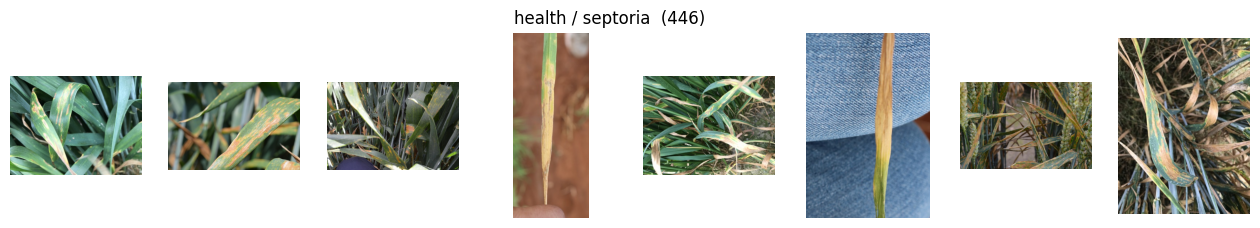

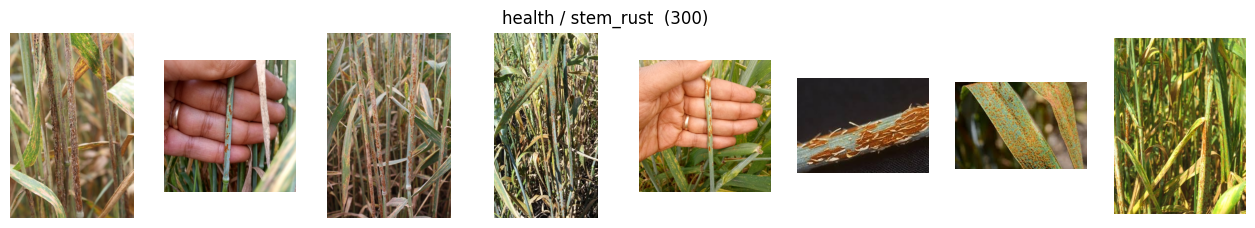

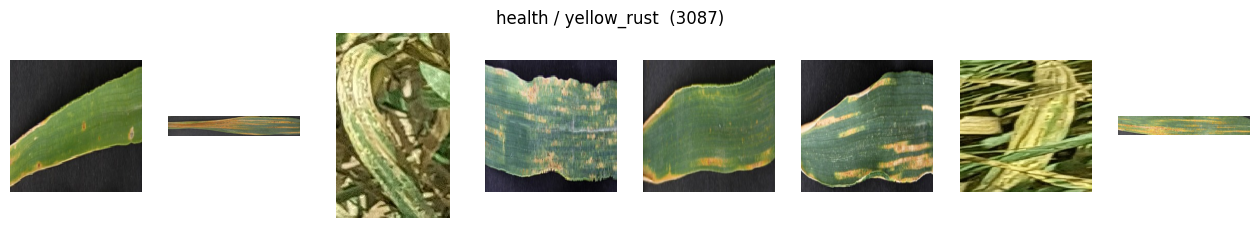

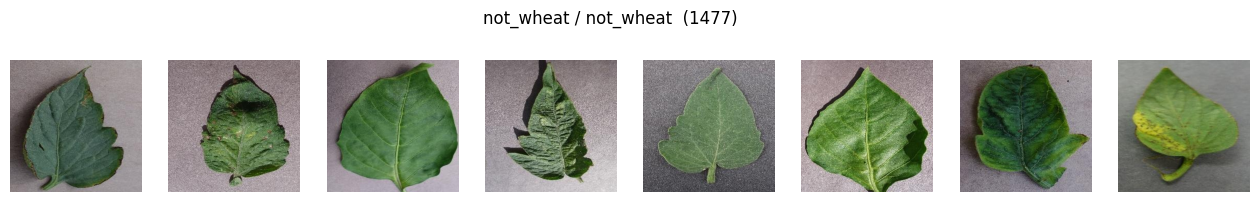

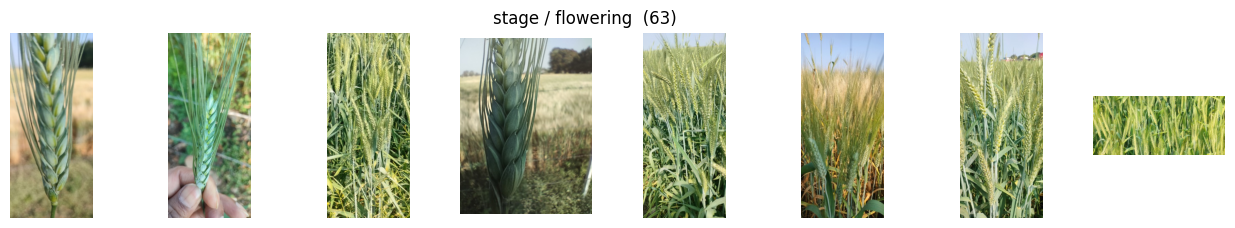

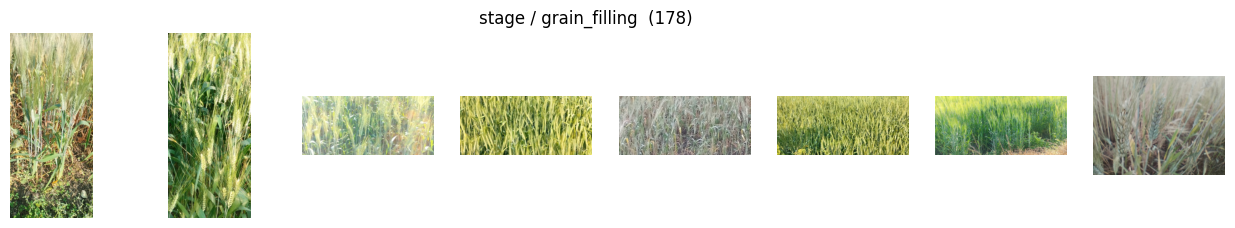

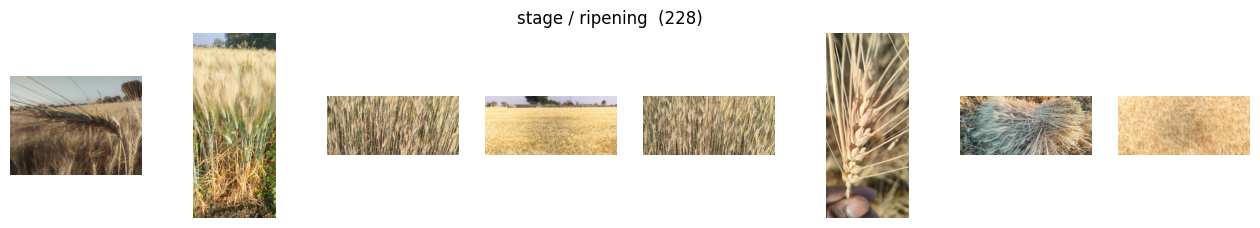

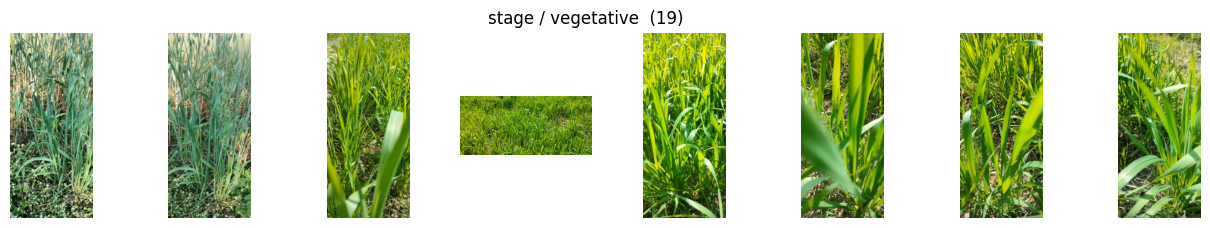

In [10]:
for (t, l), g in df.groupby(["task","label"]):
    s = g.sample(min(8, len(g)), random_state=SEED)
    fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    for a in ax: a.axis("off")
    for a, r in zip(ax, s.itertuples()): a.imshow(Image.open(OUT / r.path))
    fig.suptitle(f"{t} / {l}  ({len(g)})"); plt.show()

## Step 10: Next
1. Top right: **Save Version → Save & Run All (Commit)**.
2. When it finishes, open the version → **Output** → **New Dataset**, name it `fasl-clean`.
3. Notebook 2 (training) uses `fasl-clean` as its input.